# A9v2. 6G tarmoqlarida RIS va ultra-zich kirish nuqtalarining 3D, reliability va interference modelini yaratish

**Python + Google Colab · 2 soat / 2 часа · `VARIANT=1..15`**

A9v2 A8v2 propagation bazasini 3D RIS geometriyasi, physical aperture/Fraunhofer validity, coherent va non-coherent combining bounds, analytical–Monte Carlo verification hamda UDN activity/reuse sensitivity bilan kengaytiradi. RIS va UDN qismlari pedagogik proxy bo‘lib, full electromagnetic yoki full system-level standart simulator sifatida talqin qilinmaydi.

## 1. Model funksiyalari / Функции модели

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

C_MPS=299_792_458.0
H_BS_M=10.0
H_UT_M=1.5
_OXY_FREQ=np.array([0.,52.,53.,54.,55.,56.,57.,58.,59.,60.,61.,62.,63.,64.,65.,66.,67.,68.,100.])
_OXY_ALPHA=np.array([0.,0.,1.,2.2,4.,6.6,9.7,12.6,14.6,15.,14.6,14.3,10.5,6.8,3.9,1.9,1.,0.,0.])
VARIANTS=[
 dict(variant=1,frequency_ghz=60.,direct_condition='NLOS',bs_ue_distance_m=80.,direct_blockage_loss_db=15.,ris_x_fraction=.50,ris_y_offset_m=8.,ris_height_m=6.,ris_side_elements=64,phase_bits=2,reflection_efficiency=.80,ris_excess_loss_db=1.,ptx_dbm=30.,gtx_dbi=18.,grx_dbi=8.,bandwidth_mhz=400.,noise_figure_db=7.,snr_threshold_db=0.,udn_area_side_m=400.,udn_ptx_dbm=15.,udn_gtx_dbi=10.,udn_grx_dbi=0.,udn_sinr_threshold_db=5.,seed=901),
 dict(variant=2,frequency_ghz=28.,direct_condition='NLOS',bs_ue_distance_m=120.,direct_blockage_loss_db=20.,ris_x_fraction=.50,ris_y_offset_m=10.,ris_height_m=6.,ris_side_elements=32,phase_bits=2,reflection_efficiency=.80,ris_excess_loss_db=1.,ptx_dbm=30.,gtx_dbi=18.,grx_dbi=8.,bandwidth_mhz=400.,noise_figure_db=7.,snr_threshold_db=0.,udn_area_side_m=400.,udn_ptx_dbm=15.,udn_gtx_dbi=10.,udn_grx_dbi=0.,udn_sinr_threshold_db=5.,seed=902),
 dict(variant=3,frequency_ghz=39.,direct_condition='NLOS',bs_ue_distance_m=100.,direct_blockage_loss_db=15.,ris_x_fraction=.45,ris_y_offset_m=12.,ris_height_m=7.,ris_side_elements=32,phase_bits=2,reflection_efficiency=.75,ris_excess_loss_db=1.5,ptx_dbm=30.,gtx_dbi=18.,grx_dbi=8.,bandwidth_mhz=400.,noise_figure_db=7.,snr_threshold_db=0.,udn_area_side_m=350.,udn_ptx_dbm=16.,udn_gtx_dbi=10.,udn_grx_dbi=0.,udn_sinr_threshold_db=5.,seed=903),
 dict(variant=4,frequency_ghz=60.,direct_condition='NLOS',bs_ue_distance_m=70.,direct_blockage_loss_db=20.,ris_x_fraction=.40,ris_y_offset_m=8.,ris_height_m=5.,ris_side_elements=64,phase_bits=1,reflection_efficiency=.75,ris_excess_loss_db=1.5,ptx_dbm=29.,gtx_dbi=18.,grx_dbi=8.,bandwidth_mhz=400.,noise_figure_db=7.,snr_threshold_db=0.,udn_area_side_m=350.,udn_ptx_dbm=15.,udn_gtx_dbi=10.,udn_grx_dbi=0.,udn_sinr_threshold_db=3.,seed=904),
 dict(variant=5,frequency_ghz=73.,direct_condition='NLOS',bs_ue_distance_m=60.,direct_blockage_loss_db=15.,ris_x_fraction=.50,ris_y_offset_m=6.,ris_height_m=6.,ris_side_elements=64,phase_bits=2,reflection_efficiency=.80,ris_excess_loss_db=1.,ptx_dbm=29.,gtx_dbi=22.,grx_dbi=10.,bandwidth_mhz=800.,noise_figure_db=8.,snr_threshold_db=0.,udn_area_side_m=300.,udn_ptx_dbm=17.,udn_gtx_dbi=12.,udn_grx_dbi=2.,udn_sinr_threshold_db=3.,seed=905),
 dict(variant=6,frequency_ghz=90.,direct_condition='NLOS',bs_ue_distance_m=50.,direct_blockage_loss_db=12.,ris_x_fraction=.50,ris_y_offset_m=5.,ris_height_m=5.,ris_side_elements=64,phase_bits=3,reflection_efficiency=.85,ris_excess_loss_db=1.,ptx_dbm=28.,gtx_dbi=24.,grx_dbi=10.,bandwidth_mhz=1000.,noise_figure_db=8.,snr_threshold_db=0.,udn_area_side_m=280.,udn_ptx_dbm=18.,udn_gtx_dbi=14.,udn_grx_dbi=2.,udn_sinr_threshold_db=3.,seed=906),
 dict(variant=7,frequency_ghz=100.,direct_condition='NLOS',bs_ue_distance_m=45.,direct_blockage_loss_db=10.,ris_x_fraction=.45,ris_y_offset_m=5.,ris_height_m=5.,ris_side_elements=64,phase_bits=3,reflection_efficiency=.85,ris_excess_loss_db=1.,ptx_dbm=28.,gtx_dbi=26.,grx_dbi=12.,bandwidth_mhz=1000.,noise_figure_db=8.,snr_threshold_db=0.,udn_area_side_m=250.,udn_ptx_dbm=18.,udn_gtx_dbi=14.,udn_grx_dbi=4.,udn_sinr_threshold_db=3.,seed=907),
 dict(variant=8,frequency_ghz=28.,direct_condition='NLOS',bs_ue_distance_m=150.,direct_blockage_loss_db=20.,ris_x_fraction=.55,ris_y_offset_m=12.,ris_height_m=7.,ris_side_elements=32,phase_bits=1,reflection_efficiency=.70,ris_excess_loss_db=2.,ptx_dbm=30.,gtx_dbi=20.,grx_dbi=8.,bandwidth_mhz=200.,noise_figure_db=6.,snr_threshold_db=0.,udn_area_side_m=450.,udn_ptx_dbm=15.,udn_gtx_dbi=10.,udn_grx_dbi=0.,udn_sinr_threshold_db=5.,seed=908),
 dict(variant=9,frequency_ghz=39.,direct_condition='NLOS',bs_ue_distance_m=130.,direct_blockage_loss_db=18.,ris_x_fraction=.45,ris_y_offset_m=10.,ris_height_m=6.,ris_side_elements=64,phase_bits=2,reflection_efficiency=.75,ris_excess_loss_db=1.5,ptx_dbm=30.,gtx_dbi=20.,grx_dbi=8.,bandwidth_mhz=400.,noise_figure_db=7.,snr_threshold_db=0.,udn_area_side_m=400.,udn_ptx_dbm=16.,udn_gtx_dbi=10.,udn_grx_dbi=0.,udn_sinr_threshold_db=5.,seed=909),
 dict(variant=10,frequency_ghz=60.,direct_condition='NLOS',bs_ue_distance_m=90.,direct_blockage_loss_db=15.,ris_x_fraction=.60,ris_y_offset_m=10.,ris_height_m=6.,ris_side_elements=64,phase_bits=3,reflection_efficiency=.85,ris_excess_loss_db=1.,ptx_dbm=30.,gtx_dbi=22.,grx_dbi=10.,bandwidth_mhz=800.,noise_figure_db=8.,snr_threshold_db=0.,udn_area_side_m=380.,udn_ptx_dbm=16.,udn_gtx_dbi=12.,udn_grx_dbi=2.,udn_sinr_threshold_db=5.,seed=910),
 dict(variant=11,frequency_ghz=73.,direct_condition='NLOS',bs_ue_distance_m=75.,direct_blockage_loss_db=18.,ris_x_fraction=.50,ris_y_offset_m=8.,ris_height_m=6.,ris_side_elements=64,phase_bits=2,reflection_efficiency=.80,ris_excess_loss_db=1.,ptx_dbm=29.,gtx_dbi=24.,grx_dbi=10.,bandwidth_mhz=800.,noise_figure_db=8.,snr_threshold_db=0.,udn_area_side_m=320.,udn_ptx_dbm=17.,udn_gtx_dbi=12.,udn_grx_dbi=2.,udn_sinr_threshold_db=3.,seed=911),
 dict(variant=12,frequency_ghz=90.,direct_condition='NLOS',bs_ue_distance_m=60.,direct_blockage_loss_db=15.,ris_x_fraction=.50,ris_y_offset_m=7.,ris_height_m=5.,ris_side_elements=64,phase_bits=2,reflection_efficiency=.80,ris_excess_loss_db=1.5,ptx_dbm=28.,gtx_dbi=26.,grx_dbi=12.,bandwidth_mhz=1000.,noise_figure_db=8.,snr_threshold_db=0.,udn_area_side_m=300.,udn_ptx_dbm=18.,udn_gtx_dbi=14.,udn_grx_dbi=4.,udn_sinr_threshold_db=3.,seed=912),
 dict(variant=13,frequency_ghz=100.,direct_condition='NLOS',bs_ue_distance_m=55.,direct_blockage_loss_db=12.,ris_x_fraction=.45,ris_y_offset_m=6.,ris_height_m=5.,ris_side_elements=64,phase_bits=3,reflection_efficiency=.85,ris_excess_loss_db=1.,ptx_dbm=28.,gtx_dbi=28.,grx_dbi=12.,bandwidth_mhz=1000.,noise_figure_db=8.,snr_threshold_db=0.,udn_area_side_m=280.,udn_ptx_dbm=18.,udn_gtx_dbi=14.,udn_grx_dbi=4.,udn_sinr_threshold_db=3.,seed=913),
 dict(variant=14,frequency_ghz=28.,direct_condition='NLOS',bs_ue_distance_m=180.,direct_blockage_loss_db=22.,ris_x_fraction=.50,ris_y_offset_m=15.,ris_height_m=8.,ris_side_elements=64,phase_bits=2,reflection_efficiency=.75,ris_excess_loss_db=2.,ptx_dbm=33.,gtx_dbi=20.,grx_dbi=8.,bandwidth_mhz=200.,noise_figure_db=6.,snr_threshold_db=0.,udn_area_side_m=500.,udn_ptx_dbm=17.,udn_gtx_dbi=10.,udn_grx_dbi=0.,udn_sinr_threshold_db=5.,seed=914),
 dict(variant=15,frequency_ghz=60.,direct_condition='NLOS',bs_ue_distance_m=110.,direct_blockage_loss_db=20.,ris_x_fraction=.55,ris_y_offset_m=12.,ris_height_m=7.,ris_side_elements=64,phase_bits=2,reflection_efficiency=.80,ris_excess_loss_db=1.5,ptx_dbm=30.,gtx_dbi=24.,grx_dbi=10.,bandwidth_mhz=800.,noise_figure_db=8.,snr_threshold_db=0.,udn_area_side_m=420.,udn_ptx_dbm=17.,udn_gtx_dbi=12.,udn_grx_dbi=2.,udn_sinr_threshold_db=5.,seed=915),
]

def _check_fc(fc):
    fc=float(fc)
    if not (0.5<=fc<=100.): raise ValueError('Core A9v2 propagation uses TR 38.901 only in 0.5–100 GHz.')
    return fc

def oxygen_alpha_db_per_km(fc): return float(np.interp(_check_fc(fc),_OXY_FREQ,_OXY_ALPHA))
def oxygen_loss_db(fc,d3): return oxygen_alpha_db_per_km(fc)*float(d3)/1000.
def d3d(d2,h1,h2): return math.sqrt(float(d2)**2+(float(h1)-float(h2))**2)
def umi_breakpoint_custom(fc,h_tx,h_rx,h_e=1.0):
    a=max(float(h_tx)-h_e,0.1); b=max(float(h_rx)-h_e,0.1)
    return 4*a*b*(_check_fc(fc)*1e9)/C_MPS

def umi_los_proxy_custom(fc,d2,h_tx,h_rx):
    fc=_check_fc(fc); d2eff=max(float(d2),10.0); d3=d3d(d2eff,h_tx,h_rx); dbp=umi_breakpoint_custom(fc,h_tx,h_rx)
    pl1=32.4+21*math.log10(d3)+20*math.log10(fc)
    pl2=32.4+40*math.log10(d3)+20*math.log10(fc)-9.5*math.log10(dbp**2+(h_tx-h_rx)**2)
    return (pl1 if d2eff<=dbp else pl2)+oxygen_loss_db(fc,d3)

def umi_direct_pathloss_db(fc,d2,condition='LOS'):
    fc=_check_fc(fc); d2eff=max(float(d2),10.0); d3=d3d(d2eff,H_BS_M,H_UT_M); dbp=umi_breakpoint_custom(fc,H_BS_M,H_UT_M)
    pl1=32.4+21*math.log10(d3)+20*math.log10(fc)
    pl2=32.4+40*math.log10(d3)+20*math.log10(fc)-9.5*math.log10(dbp**2+(H_BS_M-H_UT_M)**2)
    pl_los=pl1 if d2eff<=dbp else pl2
    pln=22.4+35.3*math.log10(d3)+21.3*math.log10(fc)-0.3*(H_UT_M-1.5)
    pl=pl_los if str(condition).upper()=='LOS' else max(pl_los,pln)
    return pl+oxygen_loss_db(fc,d3)

def shadow_sigma_db(condition): return 4.0 if str(condition).upper()=='LOS' else 7.82
def noise_power_dbm(bw_mhz,nf): return -174+10*math.log10(float(bw_mhz)*1e6)+float(nf)
def phase_efficiency(bits):
    if bits is None or str(bits).lower() in ('continuous','ideal'): return 1.0
    b=int(bits); x=math.pi/(2**b); return (math.sin(x)/x)**2

def ris_physical_metrics(fc,side):
    lam=C_MPS/(float(fc)*1e9); N=int(side)**2; D=math.sqrt(N)*lam/2.; A=N*(lam/2.)**2; df=2*D**2/lam
    return lam,D,A,df

def ris_array_gain_db(N,eta,bits,excess):
    return 20*math.log10(int(N))+10*math.log10(float(eta))+10*math.log10(phase_efficiency(bits))-float(excess)

def ris_geometry(v,x_fraction=None,y_offset_m=None,h_ris_m=None):
    d=float(v['bs_ue_distance_m']); xf=float(v['ris_x_fraction'] if x_fraction is None else x_fraction); y=float(v['ris_y_offset_m'] if y_offset_m is None else y_offset_m); hr=float(v['ris_height_m'] if h_ris_m is None else h_ris_m)
    bs=np.array([0.,0.,H_BS_M]); ue=np.array([d,0.,H_UT_M]); ris=np.array([xf*d,y,hr])
    dbr2=math.hypot(ris[0]-bs[0],ris[1]-bs[1]); dru2=math.hypot(ue[0]-ris[0],ue[1]-ris[1]); dbr3=float(np.linalg.norm(ris-bs)); dru3=float(np.linalg.norm(ue-ris))
    return bs,ue,ris,dbr2,dru2,dbr3,dru3

def combine_power_dbm(p1_dbm,p2_dbm,coherent=False):
    a=10**(np.asarray(p1_dbm)/10.0); b=10**(np.asarray(p2_dbm)/10.0)
    z=(np.sqrt(a)+np.sqrt(b))**2 if coherent else a+b
    return 10*np.log10(z)

def ris_deterministic(v,side_elements=None,phase_bits=None,x_fraction=None):
    fc=float(v['frequency_ghz']); side=int(v['ris_side_elements'] if side_elements is None else side_elements); bits=v['phase_bits'] if phase_bits is None else phase_bits; N=side*side
    bs,ue,ris,dbr2,dru2,dbr3,dru3=ris_geometry(v,x_fraction=x_fraction)
    pld=umi_direct_pathloss_db(fc,v['bs_ue_distance_m'],v['direct_condition'])+float(v['direct_blockage_loss_db'])
    plbr=umi_los_proxy_custom(fc,dbr2,H_BS_M,v['ris_height_m']); plru=umi_los_proxy_custom(fc,dru2,v['ris_height_m'],H_UT_M)
    rg=ris_array_gain_db(N,v['reflection_efficiency'],bits,v['ris_excess_loss_db'])
    pdir=v['ptx_dbm']+v['gtx_dbi']+v['grx_dbi']-pld; pris=v['ptx_dbm']+v['gtx_dbi']+v['grx_dbi']-plbr-plru+rg
    pnon=float(combine_power_dbm(pdir,pris,False)); pcoh=float(combine_power_dbm(pdir,pris,True)); noise=noise_power_dbm(v['bandwidth_mhz'],v['noise_figure_db'])
    lam,D,A,df=ris_physical_metrics(fc,side); ff_br=dbr3>=df; ff_ru=dru3>=df
    return dict(frequency_ghz=fc,ris_height_m=float(v['ris_height_m']),d_br_2d_m=dbr2,d_ru_2d_m=dru2,d_br_3d_m=dbr3,d_ru_3d_m=dru3,side_elements=side,n_elements=N,phase_bits=('continuous' if bits is None or str(bits).lower() in ('continuous','ideal') else int(bits)),phase_efficiency=phase_efficiency(bits),wavelength_m=lam,ris_aperture_side_m=D,ris_physical_aperture_m2=A,fraunhofer_distance_m=df,br_far_field=ff_br,ru_far_field=ff_ru,ris_array_gain_proxy_db=rg,direct_pathloss_db=pld,br_pathloss_proxy_db=plbr,ru_pathloss_proxy_db=plru,direct_rx_dbm=pdir,ris_rx_dbm=pris,noncoherent_rx_dbm=pnon,coherent_rx_dbm=pcoh,noise_dbm=noise,direct_snr_db=pdir-noise,ris_snr_db=pris-noise,noncoherent_snr_db=pnon-noise,coherent_snr_db=pcoh-noise,coherent_gain_over_direct_db=pcoh-pdir)

def wilson_ci(k,n,z=1.96):
    p=k/n; den=1+z*z/n; center=(p+z*z/(2*n))/den; half=z*math.sqrt((p*(1-p)+z*z/(4*n))/n)/den; return center-half,center+half

def analytical_cov(mu_snr,sigma,thr): return float(norm.cdf((float(mu_snr)-float(thr))/float(sigma)))
def _ris_mc_df(v,z1,z2,z3,side_elements=None,phase_bits=None):
    b=ris_deterministic(v,side_elements,phase_bits); pdir=b['direct_rx_dbm']-shadow_sigma_db(v['direct_condition'])*z1; pris=b['ris_rx_dbm']-4*z2-4*z3
    pnon=combine_power_dbm(pdir,pris,False); pcoh=combine_power_dbm(pdir,pris,True); n=b['noise_dbm']
    return pd.DataFrame({'direct_snr_db':pdir-n,'ris_snr_db':pris-n,'noncoherent_snr_db':pnon-n,'coherent_snr_db':pcoh-n})

def ris_monte_carlo(v,n_samples=10000,side_elements=None,phase_bits=None):
    n=int(n_samples); rng=np.random.default_rng(int(v['seed'])); z1=rng.normal(size=n); z2=rng.normal(size=n); z3=rng.normal(size=n); df=_ris_mc_df(v,z1,z2,z3,side_elements,phase_bits); b=ris_deterministic(v,side_elements,phase_bits); thr=float(v['snr_threshold_db'])
    out={'n_samples':n,'direct_analytical_coverage':analytical_cov(b['direct_snr_db'],shadow_sigma_db(v['direct_condition']),thr),'ris_analytical_coverage':analytical_cov(b['ris_snr_db'],math.sqrt(32),thr)}
    for col,key in [('direct_snr_db','direct'),('ris_snr_db','ris_only'),('noncoherent_snr_db','noncoherent'),('coherent_snr_db','coherent')]:
        hits=int((df[col]>=thr).sum()); lo,hi=wilson_ci(hits,n); out[key+'_coverage']=hits/n; out[key+'_ci95_low']=lo; out[key+'_ci95_high']=hi; out[key+'_median_snr_db']=float(df[col].median()); out[key+'_p5_snr_db']=float(np.percentile(df[col],5))
    out['direct_mc_abs_error']=abs(out['direct_coverage']-out['direct_analytical_coverage']); out['ris_mc_abs_error']=abs(out['ris_only_coverage']-out['ris_analytical_coverage']); out['coherent_coverage_gain_pp']=100*(out['coherent_coverage']-out['direct_coverage'])
    return out

def ris_element_sensitivity(v,sides=(8,16,32,64),n_samples=10000):
    rng=np.random.default_rng(int(v['seed'])); z=[rng.normal(size=n_samples) for _ in range(3)]; thr=v['snr_threshold_db']; rows=[]
    for s in sides:
        b=ris_deterministic(v,side_elements=s); df=_ris_mc_df(v,*z,side_elements=s); hits=(df.coherent_snr_db>=thr).mean(); rows.append({'side_elements':s,'n_elements':s*s,'aperture_m2':b['ris_physical_aperture_m2'],'fraunhofer_m':b['fraunhofer_distance_m'],'far_field_both':bool(b['br_far_field'] and b['ru_far_field']),'coherent_coverage':hits,'median_snr_db':df.coherent_snr_db.median(),'p5_snr_db':np.percentile(df.coherent_snr_db,5)})
    return pd.DataFrame(rows)

def ris_phase_sensitivity(v,opts=(1,2,3,'continuous'),n_samples=10000):
    rng=np.random.default_rng(int(v['seed'])); z=[rng.normal(size=n_samples) for _ in range(3)]; rows=[]; thr=v['snr_threshold_db']
    for bits in opts:
        df=_ris_mc_df(v,*z,phase_bits=bits); rows.append({'phase_bits':str(bits),'phase_efficiency':phase_efficiency(bits),'quantization_loss_db':10*math.log10(phase_efficiency(bits)),'coherent_coverage':(df.coherent_snr_db>=thr).mean(),'median_snr_db':df.coherent_snr_db.median(),'p5_snr_db':np.percentile(df.coherent_snr_db,5)})
    return pd.DataFrame(rows)

def ris_position_sensitivity(v,fractions=np.linspace(.2,.8,13)):
    rows=[]
    for xf in fractions:
        b=ris_deterministic(v,x_fraction=float(xf)); rows.append({'ris_x_fraction':xf,'d_br_3d_m':b['d_br_3d_m'],'d_ru_3d_m':b['d_ru_3d_m'],'coherent_snr_db':b['coherent_snr_db'],'noncoherent_snr_db':b['noncoherent_snr_db'],'far_field_both':b['br_far_field'] and b['ru_far_field']})
    return pd.DataFrame(rows)

def ap_grid(n_ap,side):
    m=int(round(math.sqrt(n_ap))); assert m*m==n_ap; c=np.linspace(side/(2*m),side-side/(2*m),m); return np.array([(x,y) for x in c for y in c])
def udn_link_matrix(v,n_ap,n_ue=4000):
    side=v['udn_area_side_m']; rng=np.random.default_rng(int(v['seed'])+1000); ue=rng.uniform(0,side,size=(n_ue,2)); ap=ap_grid(n_ap,side); d=np.linalg.norm(ue[:,None,:]-ap[None,:,:],axis=2); de=np.maximum(d,10.); fc=v['frequency_ghz']; d3=np.sqrt(de**2+(H_BS_M-H_UT_M)**2); dbp=umi_breakpoint_custom(fc,H_BS_M,H_UT_M); pl1=32.4+21*np.log10(d3)+20*np.log10(fc); pl2=32.4+40*np.log10(d3)+20*np.log10(fc)-9.5*np.log10(dbp**2+(H_BS_M-H_UT_M)**2); pl=np.where(de<=dbp,pl1,pl2)+oxygen_alpha_db_per_km(fc)*d3/1000.; rx=v['udn_ptx_dbm']+v['udn_gtx_dbi']+v['udn_grx_dbi']-pl; return ue,ap,d,rx

def udn_simulate(v,n_ap,n_ue=4000,activity_factor=1.0,central_only=False,block_probability=0.0,block_loss_db=20.0):
    ue,ap,d,rx=udn_link_matrix(v,n_ap,n_ue); rng=np.random.default_rng(int(v['seed'])+2000+int(n_ap*10)+int(block_probability*100));
    if block_probability>0: rx=rx-np.where(rng.random(rx.shape)<block_probability,block_loss_db,0.0)
    mw=10**(rx/10); best=np.argmax(mw,axis=1); ii=np.arange(len(ue)); sig=mw[ii,best]; interf=mw.sum(axis=1)-sig; noise=10**(noise_power_dbm(v['bandwidth_mhz'],v['noise_figure_db'])/10); snr=10*np.log10(sig/noise); sinr=10*np.log10(sig/(float(activity_factor)*interf+noise)); serv=d[ii,best]
    mask=np.ones(len(ue),dtype=bool)
    if central_only:
        side=v['udn_area_side_m']; lo=.15*side; hi=.85*side; mask=(ue[:,0]>=lo)&(ue[:,0]<=hi)&(ue[:,1]>=lo)&(ue[:,1]<=hi)
    thr=v['udn_sinr_threshold_db']; return {'n_ap':n_ap,'ap_density_per_km2':n_ap/(v['udn_area_side_m']/1000)**2,'activity_factor':activity_factor,'evaluation_cohort':'central70%' if central_only else 'full','n_ue_eval':int(mask.sum()),'coverage':float((sinr[mask]>=thr).mean()),'median_sinr_db':float(np.median(sinr[mask])),'p5_sinr_db':float(np.percentile(sinr[mask],5)),'median_serving_distance_m':float(np.median(serv[mask])),'p95_serving_distance_m':float(np.percentile(serv[mask],95))}

def udn_density_sweep(v,naps=(1,4,9,16,25),n_ue=4000,activity_factor=1.0): return pd.DataFrame([udn_simulate(v,n,n_ue,activity_factor) for n in naps])
def udn_activity_sensitivity(v,n_ap=25,factors=(0.,.25,.5,1.),n_ue=4000): return pd.DataFrame([udn_simulate(v,n_ap,n_ue,f) for f in factors])
def udn_edge_check(v,n_ap=25,n_ue=4000): return pd.DataFrame([udn_simulate(v,n_ap,n_ue,1.,False),udn_simulate(v,n_ap,n_ue,1.,True)])
def udn_blockage_sensitivity(v,n_ap=25,probs=(0.,.2,.4),n_ue=4000): return pd.DataFrame([dict(block_probability=p,**udn_simulate(v,n_ap,n_ue,.5,False,p,20.)) for p in probs])
def all_variants_qa():
    rows=[]
    for v in VARIANTS:
        try:
            b=ris_deterministic(v); m=ris_monte_carlo(v,2000); u=udn_simulate(v,9,1000,1.0); ok=(0<=m['coherent_coverage']<=1 and 0<=u['coverage']<=1 and b['n_elements']>0 and 0.5<=v['frequency_ghz']<=100 and v['ris_height_m']>H_UT_M); note='near-field warning' if not (b['br_far_field'] and b['ru_far_field']) else ''
        except Exception as e: ok=False; note=str(e)
        rows.append({'variant':v['variant'],'ok':ok,'note':note})
    return pd.DataFrame(rows)


## 2. Variant: 3D RIS link budget va statistical verification

In [2]:
VARIANT=1
v=dict(VARIANTS[VARIANT-1])
base_ris=ris_deterministic(v)
mc_ris=ris_monte_carlo(v,10000)
elem_df=ris_element_sensitivity(v)
phase_df=ris_phase_sensitivity(v)
pos_df=ris_position_sensitivity(v)
display(pd.DataFrame([v]))
display(pd.DataFrame([base_ris]).round(5))
display(pd.DataFrame([mc_ris]).round(5))
print('Far-field BR/RU:',base_ris['br_far_field'],base_ris['ru_far_field'],'Fraunhofer=',round(base_ris['fraunhofer_distance_m'],3),'m')

,variant,frequency_ghz,direct_condition,bs_ue_distance_m,direct_blockage_loss_db,ris_x_fraction,ris_y_offset_m,ris_height_m,ris_side_elements,phase_bits,reflection_efficiency,ris_excess_loss_db,ptx_dbm,gtx_dbi,grx_dbi,bandwidth_mhz,noise_figure_db,snr_threshold_db,udn_area_side_m,udn_ptx_dbm,udn_gtx_dbi,udn_grx_dbi,udn_sinr_threshold_db,seed
0,1,60.0,NLOS,80.0,15.0,0.5,8.0,6.0,64,2,0.8,1.0,30.0,18.0,8.0,400.0,7.0,0.0,400.0,15.0,10.0,0.0,5.0,901


,frequency_ghz,ris_height_m,d_br_2d_m,d_ru_2d_m,d_br_3d_m,d_ru_3d_m,side_elements,n_elements,phase_bits,phase_efficiency,wavelength_m,ris_aperture_side_m,ris_physical_aperture_m2,fraunhofer_distance_m,br_far_field,ru_far_field,ris_array_gain_proxy_db,direct_pathloss_db,br_pathloss_proxy_db,ru_pathloss_proxy_db,direct_rx_dbm,ris_rx_dbm,noncoherent_rx_dbm,coherent_rx_dbm,noise_dbm,direct_snr_db,ris_snr_db,noncoherent_snr_db,coherent_snr_db,coherent_gain_over_direct_db
0,60.0,6.0,40.79216,40.79216,40.9878,41.03962,64,4096,2,0.81057,0.005,0.15989,0.02556,10.23292,True,True,69.366,143.7465,102.44359,102.45589,-87.7465,-79.53348,-78.92309,-76.6828,-80.9794,-6.7671,1.44592,2.05631,4.2966,11.06371


,n_samples,direct_analytical_coverage,ris_analytical_coverage,direct_coverage,direct_ci95_low,direct_ci95_high,direct_median_snr_db,direct_p5_snr_db,ris_only_coverage,ris_only_ci95_low,ris_only_ci95_high,ris_only_median_snr_db,ris_only_p5_snr_db,noncoherent_coverage,noncoherent_ci95_low,noncoherent_ci95_high,noncoherent_median_snr_db,noncoherent_p5_snr_db,coherent_coverage,coherent_ci95_low,coherent_ci95_high,coherent_median_snr_db,coherent_p5_snr_db,direct_mc_abs_error,ris_mc_abs_error,coherent_coverage_gain_pp
0,10000,0.19342,0.60087,0.1919,0.1843,0.19974,-6.75739,-19.7302,0.6033,0.59367,0.61285,1.39737,-7.77949,0.7493,0.74071,0.7577,3.25785,-4.71831,0.8662,0.85939,0.87273,5.26365,-2.49761,0.00152,0.00243,67.43


Far-field BR/RU: True True Fraunhofer= 10.233 m


## 3. RIS aperture, element count, phase resolution va joylashuv sensitivity

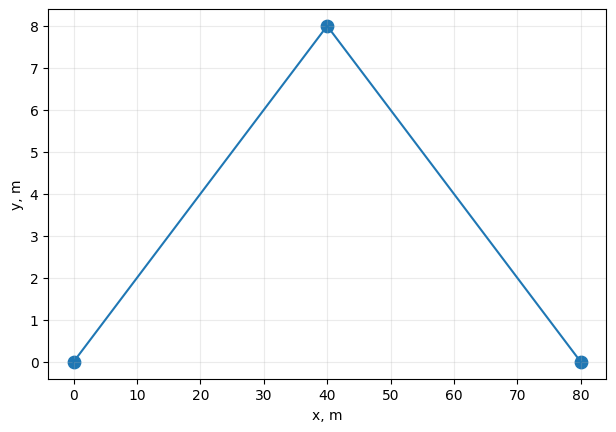

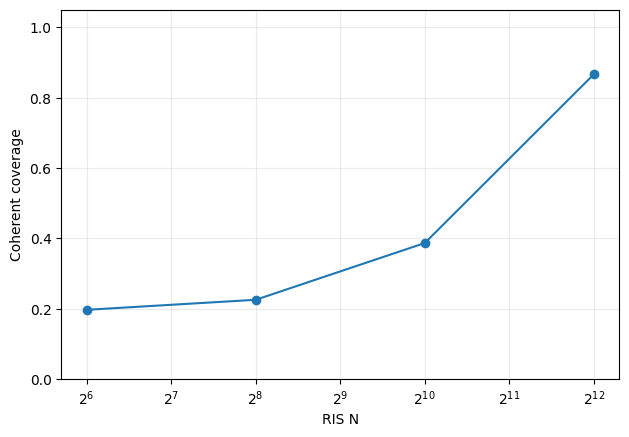

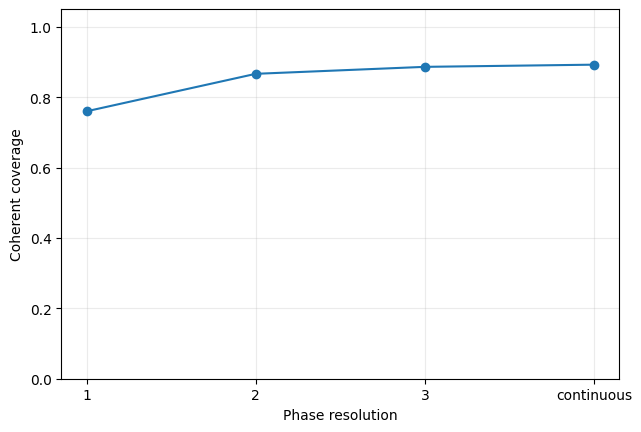

,side_elements,n_elements,aperture_m2,fraunhofer_m,far_field_both,coherent_coverage,median_snr_db,p5_snr_db
0,8,64,0.0004,0.1599,True,0.1969,-6.3151,-18.1983
1,16,256,0.0016,0.6396,True,0.2254,-5.1151,-15.0235
2,32,1024,0.0064,2.5582,True,0.3867,-1.4851,-9.8311
3,64,4096,0.0256,10.2329,True,0.8662,5.2637,-2.4976


,phase_bits,phase_efficiency,quantization_loss_db,coherent_coverage,median_snr_db,p5_snr_db
0,1,0.4053,-3.9224,0.7598,3.3052,-4.4353
1,2,0.8106,-0.9121,0.8662,5.2637,-2.4976
2,3,0.9496,-0.2244,0.8860,5.7217,-2.0374
3,continuous,1.0000,0.0000,0.8922,5.8826,-1.8720


,ris_x_fraction,d_br_3d_m,d_ru_3d_m,coherent_snr_db,noncoherent_snr_db,far_field_both
0,0.20,18.3303,64.6549,6.6973,4.9296,True
1,0.25,21.9089,60.6980,5.8849,3.9640,True
2,0.30,25.6125,56.7472,5.2728,3.2314,True
3,0.35,29.3939,52.8039,4.8293,2.6983,True
4,0.40,33.2265,48.8697,4.5290,2.3365,True
5,0.45,37.0945,44.9472,4.3547,2.1264,True
6,0.50,40.9878,41.0396,4.2966,2.0563,True
7,0.55,44.8999,37.1517,4.3514,2.1224,True
8,0.60,48.8262,33.2904,4.5219,2.3280,True
9,0.65,52.7636,29.4661,4.8176,2.6842,True


In [3]:
# 3D geometry (top view + height note)
bs,ue,ris,*_=ris_geometry(v)
plt.figure(figsize=(7.2,4.8)); plt.scatter([bs[0],ris[0],ue[0]],[bs[1],ris[1],ue[1]],s=80); plt.plot([bs[0],ris[0],ue[0]],[bs[1],ris[1],ue[1]]); plt.xlabel('x, m'); plt.ylabel('y, m'); plt.grid(alpha=.25); plt.show()
plt.figure(figsize=(7.2,4.8)); plt.plot(elem_df.n_elements,elem_df.coherent_coverage,marker='o'); plt.xscale('log',base=2); plt.ylim(0,1.05); plt.xlabel('RIS N'); plt.ylabel('Coherent coverage'); plt.grid(alpha=.25); plt.show()
plt.figure(figsize=(7.2,4.8)); plt.plot(phase_df.phase_bits,phase_df.coherent_coverage,marker='o'); plt.ylim(0,1.05); plt.xlabel('Phase resolution'); plt.ylabel('Coherent coverage'); plt.grid(alpha=.25); plt.show()
display(elem_df.round(4)); display(phase_df.round(4)); display(pos_df.round(4))

## 4. UDN densification va activity/reuse sensitivity

,n_ap,ap_density_per_km2,activity_factor,evaluation_cohort,n_ue_eval,coverage,median_sinr_db,p5_sinr_db,median_serving_distance_m,p95_serving_distance_m
0,1,6.25,1.0,full,4000,0.0228,-10.9364,-15.6052,163.5108,240.5509
1,4,25.00,1.0,full,4000,0.0770,-3.7394,-8.2057,79.9060,120.6470
2,9,56.25,1.0,full,4000,0.1375,-1.1201,-5.6882,53.6565,80.3117
3,16,100.00,1.0,full,4000,0.1530,-0.3676,-4.9377,40.2405,60.0887
4,25,156.25,1.0,full,4000,0.1568,-0.2379,-4.9592,31.8673,47.7554


,n_ap,ap_density_per_km2,activity_factor,evaluation_cohort,n_ue_eval,coverage,median_sinr_db,p5_sinr_db,median_serving_distance_m,p95_serving_distance_m
0,25,156.25,0.00,full,4000,0.5778,5.6380,1.8871,31.8673,47.7554
1,25,156.25,0.25,full,4000,0.3412,3.1508,-0.9354,31.8673,47.7554
2,25,156.25,0.50,full,4000,0.2488,1.6727,-2.6881,31.8673,47.7554
3,25,156.25,1.00,full,4000,0.1568,-0.2379,-4.9592,31.8673,47.7554


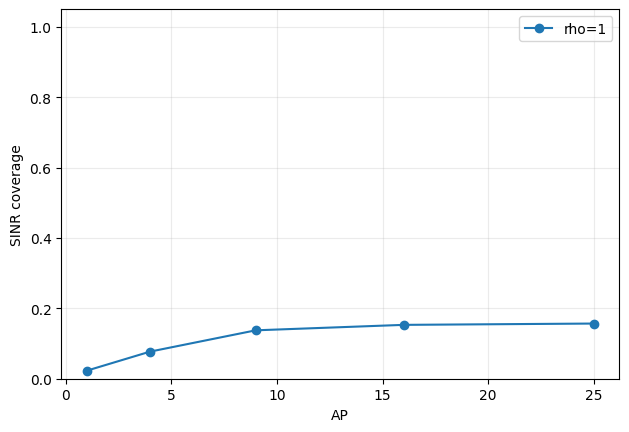

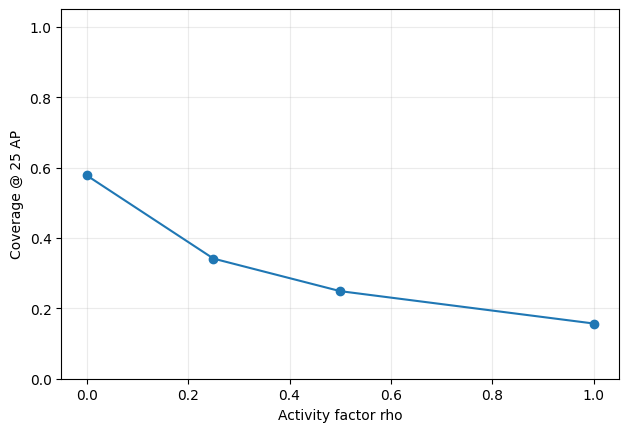

In [4]:
udn_df=udn_density_sweep(v,activity_factor=1.0)
activity_df=udn_activity_sensitivity(v,n_ap=25)
display(udn_df.round(4)); display(activity_df.round(4))
plt.figure(figsize=(7.2,4.8)); plt.plot(udn_df.n_ap,udn_df.coverage,marker='o',label='rho=1'); plt.xlabel('AP'); plt.ylabel('SINR coverage'); plt.ylim(0,1.05); plt.grid(alpha=.25); plt.legend(); plt.show()
plt.figure(figsize=(7.2,4.8)); plt.plot(activity_df.activity_factor,activity_df.coverage,marker='o'); plt.xlabel('Activity factor rho'); plt.ylabel('Coverage @ 25 AP'); plt.ylim(0,1.05); plt.grid(alpha=.25); plt.show()

## 5. Advanced/Optional: edge-effect va stochastic blockage

In [5]:
edge_df=udn_edge_check(v,25)
block_df=udn_blockage_sensitivity(v,25)
display(edge_df.round(4)); display(block_df.round(4))

,n_ap,ap_density_per_km2,activity_factor,evaluation_cohort,n_ue_eval,coverage,median_sinr_db,p5_sinr_db,median_serving_distance_m,p95_serving_distance_m
0,25,156.25,1.0,full,4000,0.1568,-0.2379,-4.9592,31.8673,47.7554
1,25,156.25,1.0,central70%,1917,0.0856,-1.9388,-5.6147,34.0165,48.8679


,block_probability,n_ap,ap_density_per_km2,activity_factor,evaluation_cohort,n_ue_eval,coverage,median_sinr_db,p5_sinr_db,median_serving_distance_m,p95_serving_distance_m
0,0.0,25,156.25,0.5,full,4000,0.2488,1.6727,-2.6881,31.8673,47.7554
1,0.2,25,156.25,0.5,full,4000,0.2240,1.2299,-5.0070,35.5418,74.5412
2,0.4,25,156.25,0.5,full,4000,0.1958,0.2983,-7.0292,41.2412,101.6818


## 6. CSV natijalarini saqlash

In [6]:
prefix=f"A9v2_variant_{VARIANT:02d}"
pd.DataFrame([base_ris]).to_csv(prefix+'_ris_link_budget.csv',index=False)
pd.DataFrame([mc_ris]).to_csv(prefix+'_ris_mc_verification.csv',index=False)
elem_df.to_csv(prefix+'_ris_element_sensitivity.csv',index=False)
phase_df.to_csv(prefix+'_ris_phase_sensitivity.csv',index=False)
pos_df.to_csv(prefix+'_ris_position_sensitivity.csv',index=False)
udn_df.to_csv(prefix+'_udn_density_sweep.csv',index=False)
activity_df.to_csv(prefix+'_udn_activity_sensitivity.csv',index=False)
edge_df.to_csv(prefix+'_udn_edge_check.csv',index=False)
block_df.to_csv(prefix+'_udn_blockage_optional.csv',index=False)
print('Saved:',prefix+'_*.csv')

Saved: A9v2_variant_01_*.csv


## 7. 15 variant QA va model-validity tekshiruvlari

In [7]:
qa=all_variants_qa(); display(qa); assert qa.ok.all(); print('OK: 15/15 variants passed core QA. Near-field warnings, if any, are shown in note.')

,variant,ok,note
0,1,True,
1,2,True,
2,3,True,
3,4,True,
4,5,True,
5,6,True,
6,7,True,
7,8,True,
8,9,True,
9,10,True,


OK: 15/15 variants passed core QA. Near-field warnings, if any, are shown in note.


## 8. Interpretatsiya chegaralari

- BS–RIS va RIS–UE uchun generalized LOS UMi **proxy** ishlatiladi; RIS balandligi 3D masofaga kiritiladi.
- Fraunhofer check far-field formulaning applicability signalidir; near-field bo‘lsa ETSI GR RIS 007 kabi near-field model kerak.
- `20log10(N)` coherent array-gain **upper-bound proxy**; physical aperture cheksiz N² gain degani emas.
- Non-coherent va coherent combining mos ravishda konservativroq reference va ideal upper boundni beradi.
- UDN activity factor o‘rtacha interference-load proxy; real scheduler/reuse/beam coordination emas.
- Central cohort edge-effectni tashxislaydi; wrap-around topology modellashtirilmagan.
- 100 GHz dan yuqori diapazonda TR 38.901 avtomatik ekstrapolyatsiya qilinmaydi.